# Z24: detección temprana de daño, paso a paso

Este notebook sigue el orden en que se tomaron las decisiones. Cada paso muestra un análisis y la decisión que sale de él.

**Principio:** todo se desarrolla como si no se tuviera información del daño, porque en un puente real solo se conoce el comportamiento del puente sano. Los datos con daño se usan solo para evaluar, al final.

**Índice**
1. [Frecuencias frente a la temperatura](#sec1)
2. [Preparación del daño](#sec2)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Fixed seed, so that any random result is always the same
SEED = 42
np.random.seed(SEED)

# Input files (in the parent folder, bridge-z24)
FREQUENCIES_FILE = "../results/ems_natural_frequencies.csv"
ENVIRONMENT_FILE = "../cache/ems_inventory.csv"

# Important dates
PREP_START = pd.Timestamp("1998-08-05")           # start of the installation of the pier lowering system
DAMAGE_START = pd.Timestamp("1998-08-11 13:15")   # first pier lowering

MODES = [1, 2, 3]


# Shows a table with its caption above it
def show_table(table, number, caption, decimals=3):
    display(Markdown(f"**Tabla {number}.** {caption}"))
    display(table.style.hide(axis="index").format(precision=decimals))


# Shows a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

---
<a id="sec1"></a>
## 1. Frecuencias frente a la temperatura

**Datos:**
- Frecuencias de los modos 1, 2 y 3 ($f_1$, $f_2$, $f_3$), identificadas cada hora en `z24_natural_frequencies_ems.ipynb`.
- Temperatura del pavimento, $T$: promedio de los sensores TP1 y TP2. Los códigos de error del registrador (valores de 100 °C o más) se dejan vacíos.

Solo se miran las mediciones del puente sano, antes del 05.08.1998.

In [2]:
# 1. Frequencies and temperatures (pavement TP and slab TDT)
frequencies = pd.read_csv(FREQUENCIES_FILE, parse_dates=["start"])
temperatures = pd.read_csv(ENVIRONMENT_FILE, usecols=["code", "TP1", "TP2", "TDT1", "TDT2"])

# 2. Error codes of the data logger (for example 3276.7) are replaced by NaN
for column in ["TP1", "TP2", "TDT1", "TDT2"]:
    temperatures.loc[temperatures[column].abs() >= 100, column] = np.nan

# 3. Pavement temperature (T) and slab temperature
temperatures["T"] = temperatures[["TP1", "TP2"]].mean(axis=1)
temperatures["T_slab"] = temperatures[["TDT1", "TDT2"]].mean(axis=1)

# 4. One table with both, in time order
data = pd.merge(frequencies, temperatures[["code", "T", "T_slab"]], on="code", how="left")
data = data.sort_values("start").reset_index(drop=True)

# 5. Healthy bridge: measurements before the damage preparation
healthy = data[data["start"] < PREP_START]

correlation = healthy["T"].corr(healthy["T_slab"])
print(f"Healthy measurements: {len(healthy)}, from {healthy['start'].min():%d.%m.%Y} to {healthy['start'].max():%d.%m.%Y}")
print(f"Correlation between pavement and slab temperature: {correlation:.3f}")

Healthy measurements: 4821, from 10.11.1997 to 04.08.1998
Correlation between pavement and slab temperature: 0.977


La temperatura del pavimento y la de la losa están casi perfectamente correlacionadas, así que dan la misma información. Se usa la del **pavimento**.

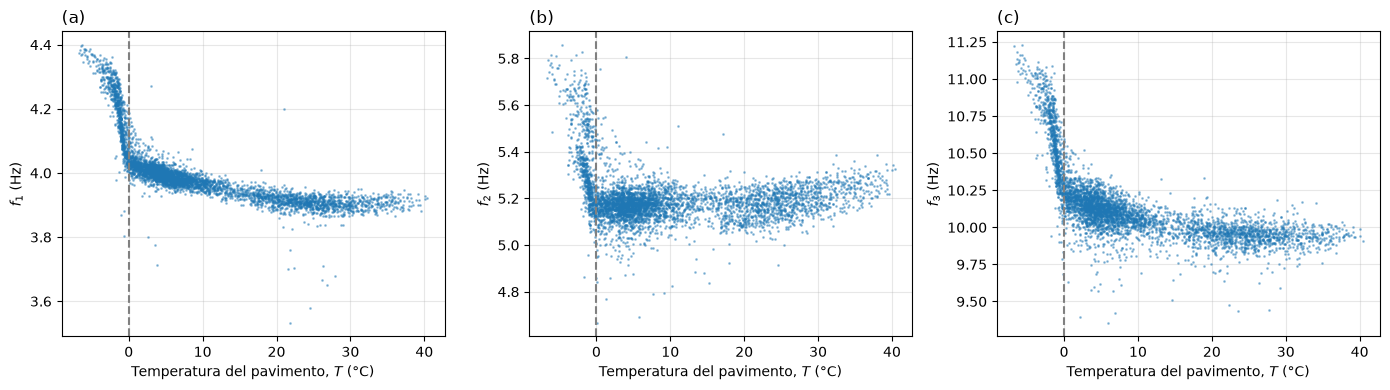

**Figura 1.** Frecuencia frente a la temperatura del pavimento, puente sano (10.11.1997 al 04.08.1998): (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(healthy["T"], healthy["f1"], ".", markersize=2, alpha=0.4)
axes[1].plot(healthy["T"], healthy["f2"], ".", markersize=2, alpha=0.4)
axes[2].plot(healthy["T"], healthy["f3"], ".", markersize=2, alpha=0.4)

axes[0].set_ylabel("$f_1$ (Hz)")
axes[1].set_ylabel("$f_2$ (Hz)")
axes[2].set_ylabel("$f_3$ (Hz)")
axes[0].set_title("(a)", loc="left")
axes[1].set_title("(b)", loc="left")
axes[2].set_title("(c)", loc="left")
for ax in axes:
    ax.axvline(0, color="gray", linestyle="--")     # 0 °C
    ax.set_xlabel("Temperatura del pavimento, $T$ (°C)")
    ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 1, "Frecuencia frente a la temperatura del pavimento, puente sano (10.11.1997 al 04.08.1998): "
            "(a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.")

**Qué se ve:**

- **Sobre 0 °C:** las frecuencias bajan poco a poco al subir la temperatura ($f_1$, de unos 4.05 Hz a 0 °C a 3.90 Hz a 30 °C). $f_2$ casi no cambia.
- **Bajo 0 °C:** las tres suben con fuerza ($f_1$ hasta 4.4 Hz, $f_2$ hasta 5.8 Hz, $f_3$ hasta 11.2 Hz). El asfalto se congela y rigidiza el tablero.
- **Dispersión bajo 0 °C:** con la misma temperatura, la frecuencia cambia mucho (por ejemplo, $f_2$ entre 5.2 y 5.8 Hz a −2 °C). La temperatura del momento no basta: importa también cuánto tiempo lleva el puente con frío.
- **Puntos aislados** lejos de la nube: errores de identificación de la frecuencia. Se conservan, porque el monitoreo real también los tendrá.

**Consecuencia:** la relación no es lineal y tiene un quiebre en 0 °C. El modelo necesitará algo más que la temperatura del momento.

---
<a id="sec2"></a>
## 2. Preparación del daño

Del 05.08.1998 al primer descenso de la pila (11.08.1998, 13:15) se instaló el sistema para bajarla: se cortaron tres tramos de la pila Koppigen y se reemplazaron por piezas de acero con gatos hidráulicos (Tabla 2 de `z24_modal_distributions.ipynb`). Son trabajos planificados, así que sus fechas se conocerían también en un puente real.

¿Cambiaron las frecuencias? Se marcan esas mediciones sobre la nube del puente sano (Figura 2) y en el tiempo (Figura 3).

Preparation measurements: 158


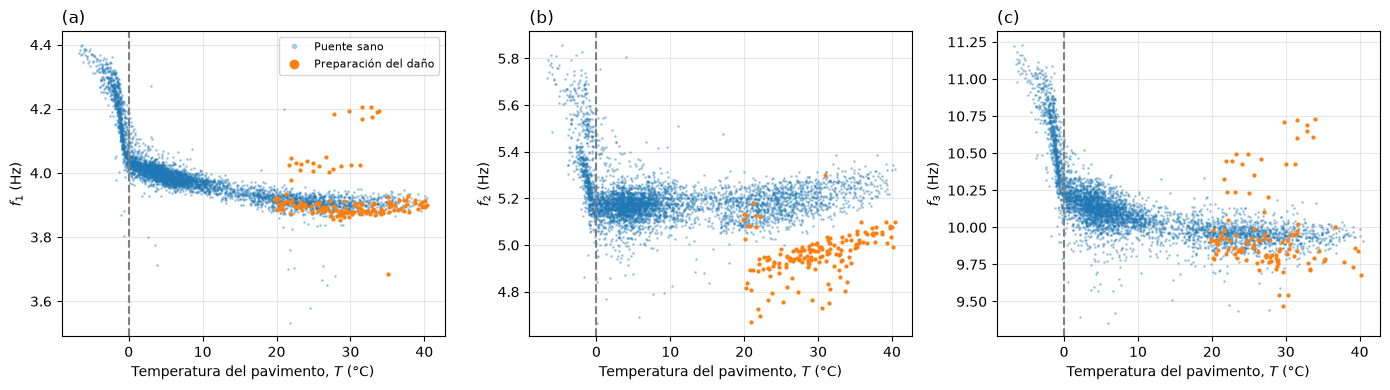

**Figura 2.** Mediciones de la preparación del daño (naranja, 05.08.1998 al 11.08.1998, 13:15) sobre las del puente sano (azul): (a) modo 1, (b) modo 2 y (c) modo 3.

In [4]:
# Measurements of the damage preparation
preparation = data[(data["start"] >= PREP_START) & (data["start"] < DAMAGE_START)]
print(f"Preparation measurements: {len(preparation)}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i in range(3):
    column = f"f{MODES[i]}"
    axes[i].plot(healthy["T"], healthy[column], ".", markersize=2, alpha=0.3, color="tab:blue", label="Puente sano")
    axes[i].plot(preparation["T"], preparation[column], ".", markersize=4, color="tab:orange",
                 label="Preparación del daño")
    axes[i].axvline(0, color="gray", linestyle="--")
    axes[i].set_xlabel("Temperatura del pavimento, $T$ (°C)")
    axes[i].set_ylabel(f"$f_{MODES[i]}$ (Hz)")
    axes[i].set_title(["(a)", "(b)", "(c)"][i], loc="left")
    axes[i].grid(alpha=0.3)
axes[0].legend(markerscale=3, fontsize=8)

fig.tight_layout()
show_figure(fig, 2, "Mediciones de la preparación del daño (naranja, 05.08.1998 al 11.08.1998, 13:15) sobre las del "
            "puente sano (azul): (a) modo 1, (b) modo 2 y (c) modo 3.")

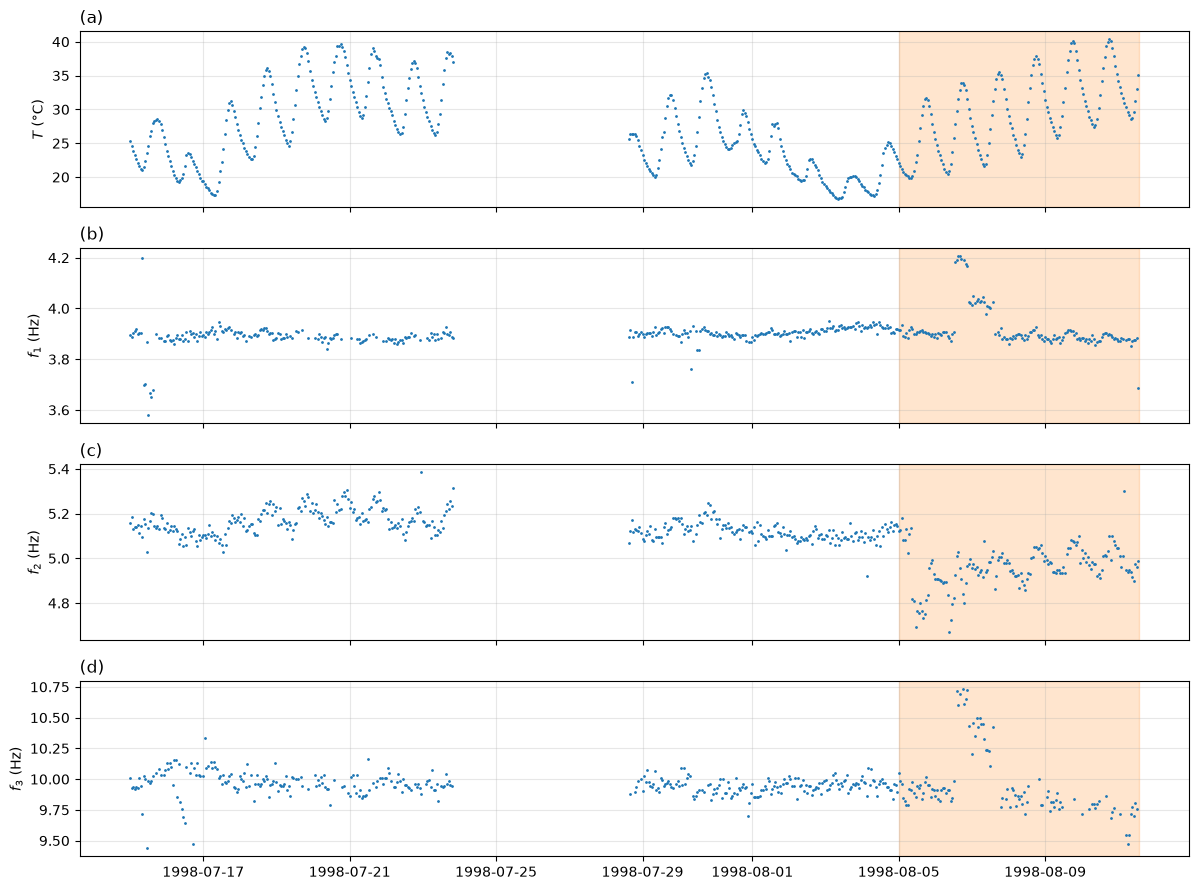

**Figura 3.** Del 15.07.1998 al primer descenso de la pila: (a) temperatura del pavimento, (b) $f_1$, (c) $f_2$ y (d) $f_3$. La franja naranja es la preparación del daño.

In [5]:
# Three weeks before the preparation and the preparation itself
window = data[(data["start"] >= pd.Timestamp("1998-07-15")) & (data["start"] < DAMAGE_START)]

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
axes[0].plot(window["start"], window["T"], ".", markersize=2)
axes[1].plot(window["start"], window["f1"], ".", markersize=2)
axes[2].plot(window["start"], window["f2"], ".", markersize=2)
axes[3].plot(window["start"], window["f3"], ".", markersize=2)

axes[0].set_ylabel("$T$ (°C)")
axes[1].set_ylabel("$f_1$ (Hz)")
axes[2].set_ylabel("$f_2$ (Hz)")
axes[3].set_ylabel("$f_3$ (Hz)")
labels = ["(a)", "(b)", "(c)", "(d)"]
for i in range(4):
    axes[i].axvspan(PREP_START, DAMAGE_START, color="tab:orange", alpha=0.2)    # preparation
    axes[i].set_title(labels[i], loc="left")
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 3, "Del 15.07.1998 al primer descenso de la pila: (a) temperatura del pavimento, (b) $f_1$, (c) $f_2$ "
            "y (d) $f_3$. La franja naranja es la preparación del daño.")

Para medirlo, se comparan las frecuencias con temperaturas parecidas: las mediciones entre 20 y 35 °C del puente sano y de la preparación.

In [6]:
# Median frequency of the healthy bridge and of the preparation, both between 20 and 35 °C
healthy_warm = healthy[(healthy["T"] >= 20) & (healthy["T"] <= 35)]
preparation_warm = preparation[(preparation["T"] >= 20) & (preparation["T"] <= 35)]

rows = []
for mode in MODES:
    column = f"f{mode}"
    healthy_median = healthy_warm[column].median()
    preparation_median = preparation_warm[column].median()
    rows.append({
        "Modo": mode,
        "Puente sano (Hz)": healthy_median,
        "Preparación (Hz)": preparation_median,
        "Cambio (%)": 100 * (preparation_median - healthy_median) / healthy_median,
    })
print(f"Measurements between 20 and 35 °C: healthy {len(healthy_warm)}, preparation {len(preparation_warm)}")
show_table(pd.DataFrame(rows), 1, "Mediana de la frecuencia con temperatura del pavimento entre 20 y 35 °C: puente "
           "sano y preparación del daño.")

Measurements between 20 and 35 °C: healthy 957, preparation 126


**Tabla 1.** Mediana de la frecuencia con temperatura del pavimento entre 20 y 35 °C: puente sano y preparación del daño.

Modo,Puente sano (Hz),Preparación (Hz),Cambio (%)
1,3.907,3.892,-0.373
2,5.192,4.946,-4.734
3,9.948,9.886,-0.621


**Qué se ve:**

- **$f_2$** baja el mismo 05.08 y se queda debajo de la nube del puente sano durante toda la preparación: −4.7 % a la misma temperatura (Tabla 1, Figura 3c).
- **$f_1$ y $f_3$** suben durante cerca de un día (06–07.08, hasta 4.2 y 10.7 Hz) y después vuelven cerca de sus valores sanos (Figura 3b y 3d).
- Un aumento de masa solo bajaría las frecuencias. Que unas suban y otras bajen indica que cambiaron las **condiciones de apoyo de la pila** mientras se cortaba y se ponían los gatos.

**Decisión:** las 158 mediciones de la preparación no representan al puente sano ni al daño que se busca. Se **excluyen del entrenamiento, de la validación y de la prueba**. Su temperatura sí se seguirá usando para calcular la historia de la temperatura, porque es una medición válida del ambiente.